<a href="https://colab.research.google.com/github/vigneshhh34/Heritage-Lens/blob/main/notebooks/heritage_lens_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
PROJECT = '/content/drive/MyDrive/heritage-lens'
print(os.listdir(PROJECT))

['datasets', 'models', 'outputs', 'notebooks', 'test_images']


In [2]:
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
print('Kaggle token loaded')

Kaggle token loaded


In [3]:
for ds in ["jungseolin/international-architectural-styles-combined",
           "gustavoachavez/architectural-styles-periods-dataset"]:
    print("=====", ds)
    !kaggle datasets files -d {ds} | head -n 15

===== jungseolin/international-architectural-styles-combined
Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5FM60NX48x11H4d6AeyQy6VtaF_xdixhIivYsa825m5ee0WV5gOGe2YVwKF8_ujC4zdVUxtBWEpL55XKJH2xh7Fe16Hdj1pZjAeKBOV6nLEiOEU8UcMmIAI5SRAcegTgYI7F-W5_T-xvuaI7Hm65Jk
name                                       size  creationDate                
---------------------------------------  ------  --------------------------  
Achaemenid architecture/data/000000.jpg   59291  2024-12-02 00:11:22.946000  
Achaemenid architecture/data/000002.jpg   72217  2024-12-02 00:11:22.951000  
Achaemenid architecture/data/000003.jpg   31651  2024-12-02 00:11:22.939000  
Achaemenid architecture/data/000004.jpg   45868  2024-12-02 00:11:22.939000  
Achaemenid architecture/data/000005.jpg   54748  2024-12-02 00:11:22.946000  
Achaemenid architecture/data/000007.jpg   60399  2024-12-02 00:11:22.939000  
Achaemenid architecture/data/000008.jpg   57663  2024-12-02 00:11:22.951000  
Achaemenid architecture/data/000011.jpg   7

International Architectural Styles - Combined is an extended version of my original dataset, which you can find at https://www.kaggle.com/datasets/jungseolin/international-architectural-styles  

It contains 45 total architectural styles. The latter 25 styles are a combination of the works of 

	- Danci, Marian Dumitru (@dumitrux) 
		https://www.kaggle.com/datasets/dumitrux/architectural-styles-dataset
	- Xu, Zhe & Zhang, Ya & Tao, Dacheng & Wu, Junjie & Tsoi, Ah. (2014). Architectural Style Classification Using Multinomial Latent Logistic Regression. 10.1007/978-3-319-10590-1_39. 
		https://www.kaggle.com/datasets/wwymak/architecture-dataset

My contribution to the dataset is composed entirely of images from Wikimedia Commons. For those 20 styles, each folder includes an attributes.txt file with the title, creator, source, and copyright information of each image with the header number corresponding to the label of the image under style/data. 

The styles included in this dataset are: 

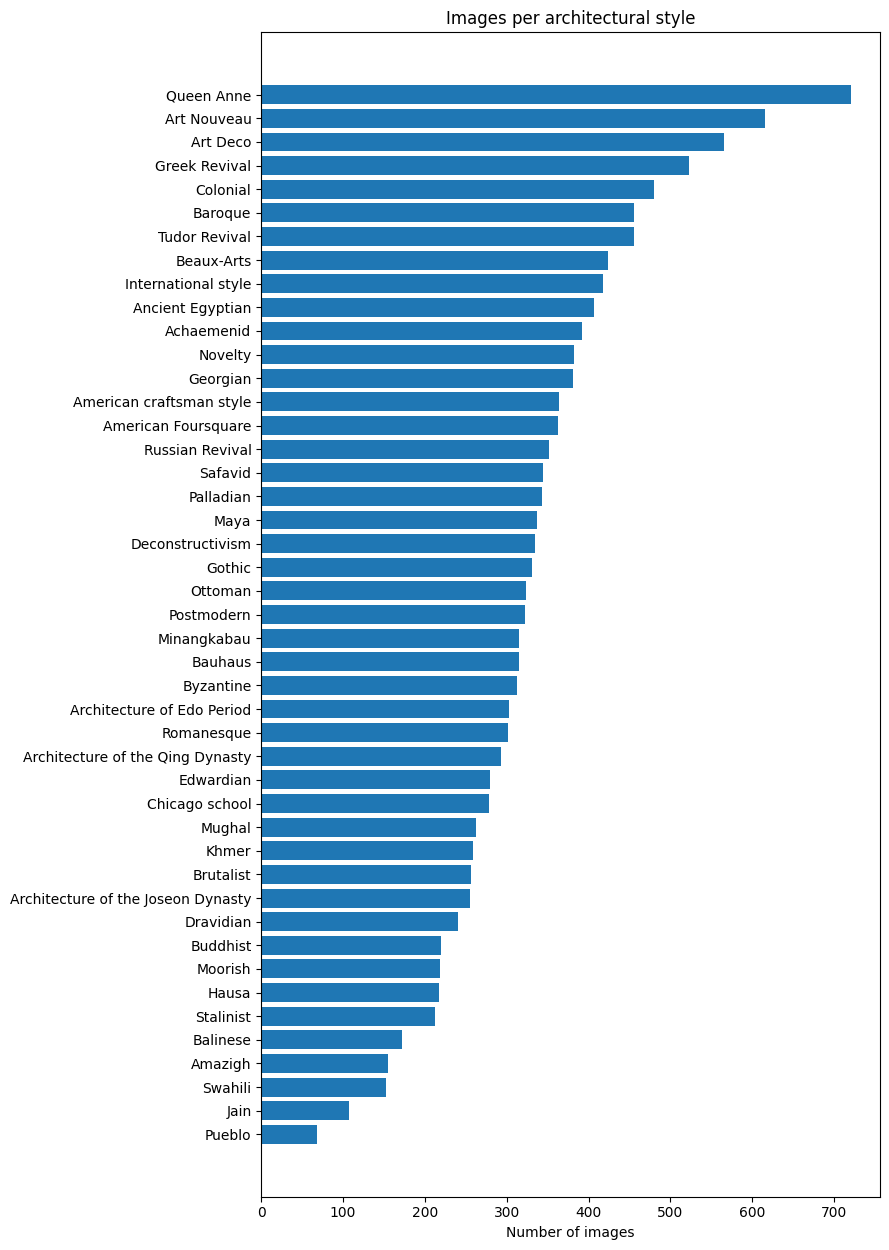

In [14]:
import os, glob
import matplotlib.pyplot as plt

ROOT = '/content/data'

# README
print(open(f'{ROOT}/README.txt').read()[:1500])
print('-' * 60)

# count images per style
classes = sorted(d for d in os.listdir(ROOT) if os.path.isdir(f'{ROOT}/{d}'))
counts = {}
for c in classes:
    files = glob.glob(f'{ROOT}/{c}/data/**/*.*', recursive=True)
    counts[c] = len([f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

print(len(classes), 'styles,', sum(counts.values()), 'images in total')
for c, n in sorted(counts.items(), key=lambda x: x[1]):
    print(f'{n:6d}  {c}')

# chart
items = sorted(counts.items(), key=lambda x: x[1])
plt.figure(figsize=(9, max(5, len(items) * 0.28)))
plt.barh([k.replace(' architecture', '') for k, v in items], [v for k, v in items])
plt.xlabel('Number of images')
plt.title('Images per architectural style')
plt.tight_layout()
plt.show()

In [13]:
!kaggle datasets download -d jungseolin/international-architectural-styles-combined -p /content/data --unzip
!find /content/data -maxdepth 2 | head -n 40

Dataset URL: https://www.kaggle.com/datasets/jungseolin/international-architectural-styles-combined
License(s): CC-BY-SA-4.0
100% 1.71G/1.71G [00:28<00:00, 64.6MB/s]

/content/data
/content/data/Dravidian architecture
/content/data/Dravidian architecture/attributes.txt
/content/data/Dravidian architecture/data
/content/data/Russian Revival architecture
/content/data/Russian Revival architecture/data
/content/data/American Foursquare architecture
/content/data/American Foursquare architecture/data
/content/data/Ottoman architecture
/content/data/Ottoman architecture/attributes.txt
/content/data/Ottoman architecture/data
/content/data/README.txt
/content/data/Ancient Egyptian architecture
/content/data/Ancient Egyptian architecture/data
/content/data/Romanesque architecture
/content/data/Romanesque architecture/data
/content/data/Hausa architecture
/content/data/Hausa architecture/attributes.txt
/content/data/Hausa architecture/data
/content/data/Achaemenid architecture
/content/data/Ach

Found: 14823 images, 45 styles
Dropping: {'Jain architecture': np.int64(107), 'Pueblo architecture': np.int64(68)}
Corrupt images removed: 0

Styles kept: 43
split
train    11718
val       1465
test      1465
Name: count, dtype: int64

Median image size: 800 x 600


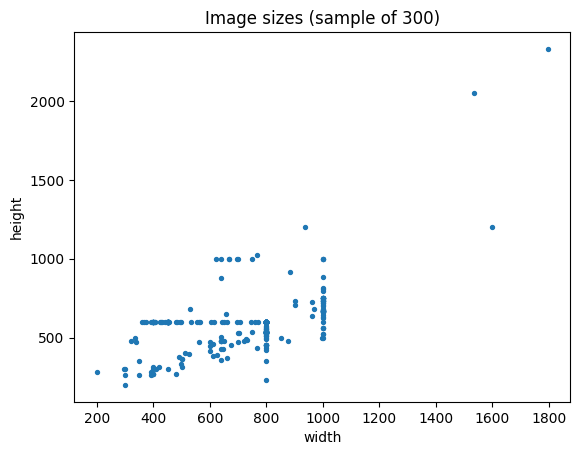

In [15]:
import os, glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

ROOT = '/content/data'
PROJECT = '/content/drive/MyDrive/heritage-lens'
MIN_IMAGES = 150

# 1. list every image with its style
rows = []
for style in sorted(d for d in os.listdir(ROOT) if os.path.isdir(f'{ROOT}/{d}')):
    for p in glob.glob(f'{ROOT}/{style}/data/**/*.*', recursive=True):
        if p.lower().endswith(('.jpg', '.jpeg', '.png')):
            rows.append({'path': os.path.relpath(p, ROOT), 'label': style})
df = pd.DataFrame(rows)
print('Found:', len(df), 'images,', df.label.nunique(), 'styles')

# 2. drop tiny classes
counts = df.label.value_counts()
dropped = counts[counts < MIN_IMAGES]
print('Dropping:', dict(dropped))
df = df[df.label.isin(counts[counts >= MIN_IMAGES].index)].copy()

# 3. remove unreadable images
def readable(rel):
    try:
        with Image.open(f'{ROOT}/{rel}') as im:
            im.verify()
        return True
    except Exception:
        return False
df['ok'] = df.path.map(readable)
print('Corrupt images removed:', (~df.ok).sum())
df = df[df.ok].drop(columns='ok').reset_index(drop=True)

# 4. stratified 80/10/10 split
train, temp = train_test_split(df, test_size=0.2, stratify=df.label, random_state=42)
val, test = train_test_split(temp, test_size=0.5, stratify=temp.label, random_state=42)
train['split'], val['split'], test['split'] = 'train', 'val', 'test'
final = pd.concat([train, val, test]).reset_index(drop=True)

os.makedirs(f'{PROJECT}/datasets', exist_ok=True)
final.to_csv(f'{PROJECT}/datasets/splits.csv', index=False)

print('\nStyles kept:', final.label.nunique())
print(final.split.value_counts())

# 5. quick look at image sizes (sample of 300)
sizes = [Image.open(f'{ROOT}/{p}').size for p in final.sample(300, random_state=1).path]
w, h = zip(*sizes)
print(f'\nMedian image size: {int(pd.Series(w).median())} x {int(pd.Series(h).median())}')
plt.scatter(w, h, s=8); plt.xlabel('width'); plt.ylabel('height')
plt.title('Image sizes (sample of 300)'); plt.show()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 134MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 1/8 | loss 2.210 | val acc 0.653 | val top-3 0.853 | 129s
Epoch 2/8 | loss 1.467 | val acc 0.704 | val top-3 0.895 | 125s
Epoch 3/8 | loss 1.229 | val acc 0.718 | val top-3 0.898 | 130s
Epoch 4/8 | loss 1.071 | val acc 0.741 | val top-3 0.913 | 135s
Epoch 5/8 | loss 0.965 | val acc 0.760 | val top-3 0.913 | 134s
Epoch 6/8 | loss 0.888 | val acc 0.772 | val top-3 0.917 | 135s
Epoch 7/8 | loss 0.848 | val acc 0.777 | val top-3 0.916 | 136s
Epoch 8/8 | loss 0.832 | val acc 0.780 | val top-3 0.917 | 136s


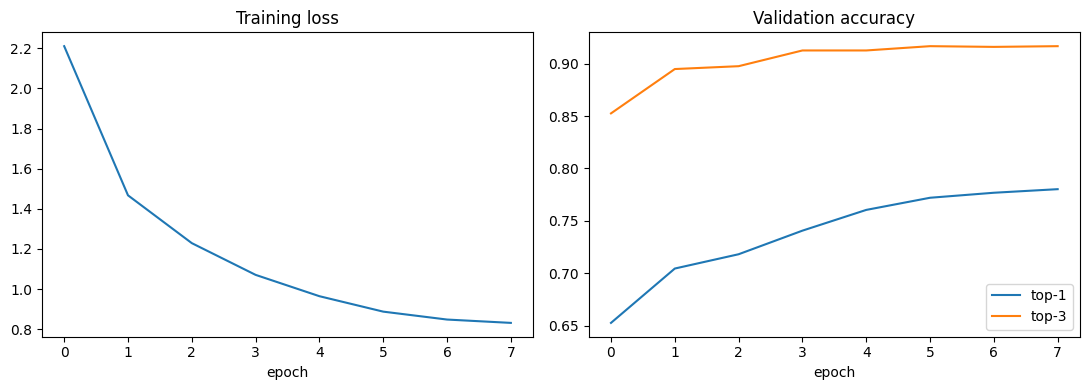

Best val accuracy: 0.7802047781569966


In [16]:
import os, json, time
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

ROOT = '/content/data'
PROJECT = '/content/drive/MyDrive/heritage-lens'
assert os.path.exists(ROOT), 'Data folder missing: rerun the Kaggle download cell first'
dev = 'cuda'
EPOCHS, BATCH = 8, 64

# ---------- data ----------
df = pd.read_csv(f'{PROJECT}/datasets/splits.csv')
classes = sorted(df.label.unique())
c2i = {c: i for i, c in enumerate(classes)}
os.makedirs(f'{PROJECT}/models', exist_ok=True)
json.dump(classes, open(f'{PROJECT}/models/classes.json', 'w'))

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, d, tf):
        self.p, self.tf = d.path.tolist(), tf
        self.y = [c2i[l] for l in d.label]
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        img = Image.open(f'{ROOT}/{self.p[i]}').convert('RGB')
        return self.tf(img), self.y[i]

tr, va = df[df.split == 'train'], df[df.split == 'val']
train_dl = DataLoader(DS(tr, train_tf), BATCH, shuffle=True, num_workers=4, pin_memory=True, drop_last=True)
val_dl = DataLoader(DS(va, eval_tf), BATCH, shuffle=False, num_workers=4, pin_memory=True)

# class weights (rarer styles count more)
cnt = tr.label.value_counts().reindex(classes).values
weights = torch.tensor(cnt.sum() / (len(classes) * cnt), dtype=torch.float32).to(dev)

# ---------- model ----------
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(classes)))
model = model.to(dev)

loss_fn = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.1)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')

# ---------- resume if a checkpoint exists ----------
LAST, BEST = f'{PROJECT}/models/last.pt', f'{PROJECT}/models/best.pt'
start, best, hist = 0, 0.0, {'loss': [], 'val_acc': [], 'val_top3': []}
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location=dev, weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
    start, best, hist = ck['epoch'], ck['best'], ck['hist']
    print(f'Resuming from epoch {start}')

def evaluate(dl):
    model.eval(); c1 = c3 = n = 0
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for x, y in dl:
            out = model(x.to(dev)); y = y.to(dev)
            top3 = out.topk(3, 1).indices
            c1 += (top3[:, 0] == y).sum().item()
            c3 += (top3 == y[:, None]).any(1).sum().item()
            n += len(y)
    return c1 / n, c3 / n

# ---------- train ----------
for ep in range(start, EPOCHS):
    model.train(); t0 = time.time(); run = 0; steps = 0
    for x, y in train_dl:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        run += loss.item(); steps += 1
    sched.step()
    acc, top3 = evaluate(val_dl)
    hist['loss'].append(run / steps); hist['val_acc'].append(acc); hist['val_top3'].append(top3)
    print(f'Epoch {ep+1}/{EPOCHS} | loss {run/steps:.3f} | val acc {acc:.3f} | val top-3 {top3:.3f} | {time.time()-t0:.0f}s')
    if acc > best:
        best = acc; torch.save({'model': model.state_dict(), 'classes': classes}, BEST)
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'epoch': ep + 1, 'best': best, 'hist': hist}, LAST)

# ---------- curves for the report ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist['loss']); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(hist['val_acc'], label='top-1'); ax[1].plot(hist['val_top3'], label='top-3')
ax[1].set_title('Validation accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Best val accuracy:', best)

Test images       : 1465
Top-1 accuracy    : 0.799
Top-3 accuracy    : 0.925
Macro precision   : 0.809
Macro recall      : 0.809
Macro F1          : 0.806
Weighted F1       : 0.798

--- 8 hardest styles (lowest F1) ---
                     precision  recall  f1-score  support
Beaux-Arts               0.595   0.512     0.550     43.0
Colonial                 0.667   0.500     0.571     48.0
Edwardian                0.543   0.679     0.603     28.0
Brutalist                0.625   0.600     0.612     25.0
Bauhaus                  0.568   0.677     0.618     31.0
Postmodern               0.704   0.594     0.644     32.0
International style      0.711   0.643     0.675     42.0
Georgian                 0.692   0.711     0.701     38.0

--- 8 easiest styles (highest F1) ---
                  precision  recall  f1-score  support
Ancient Egyptian      0.973   0.878     0.923     41.0
Hausa                 0.913   0.955     0.933     22.0
Joseon Dynasty        0.958   0.920     0.939     25.0


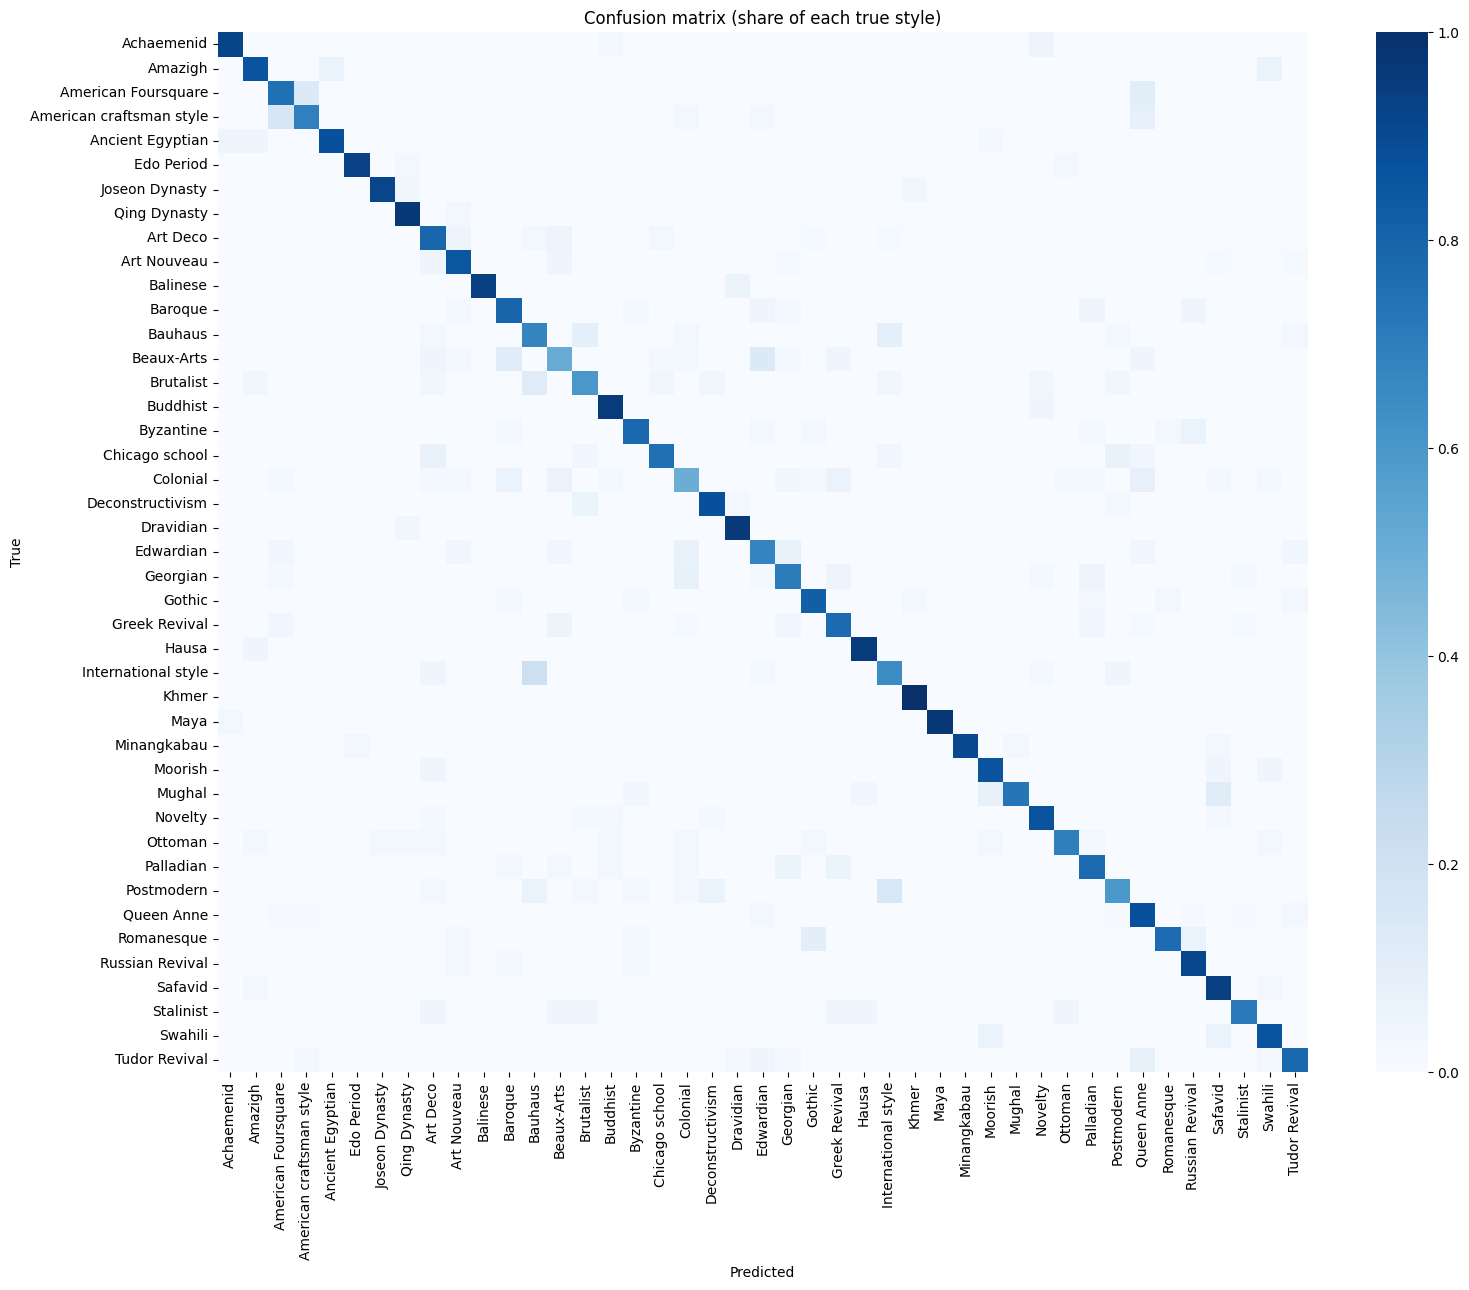

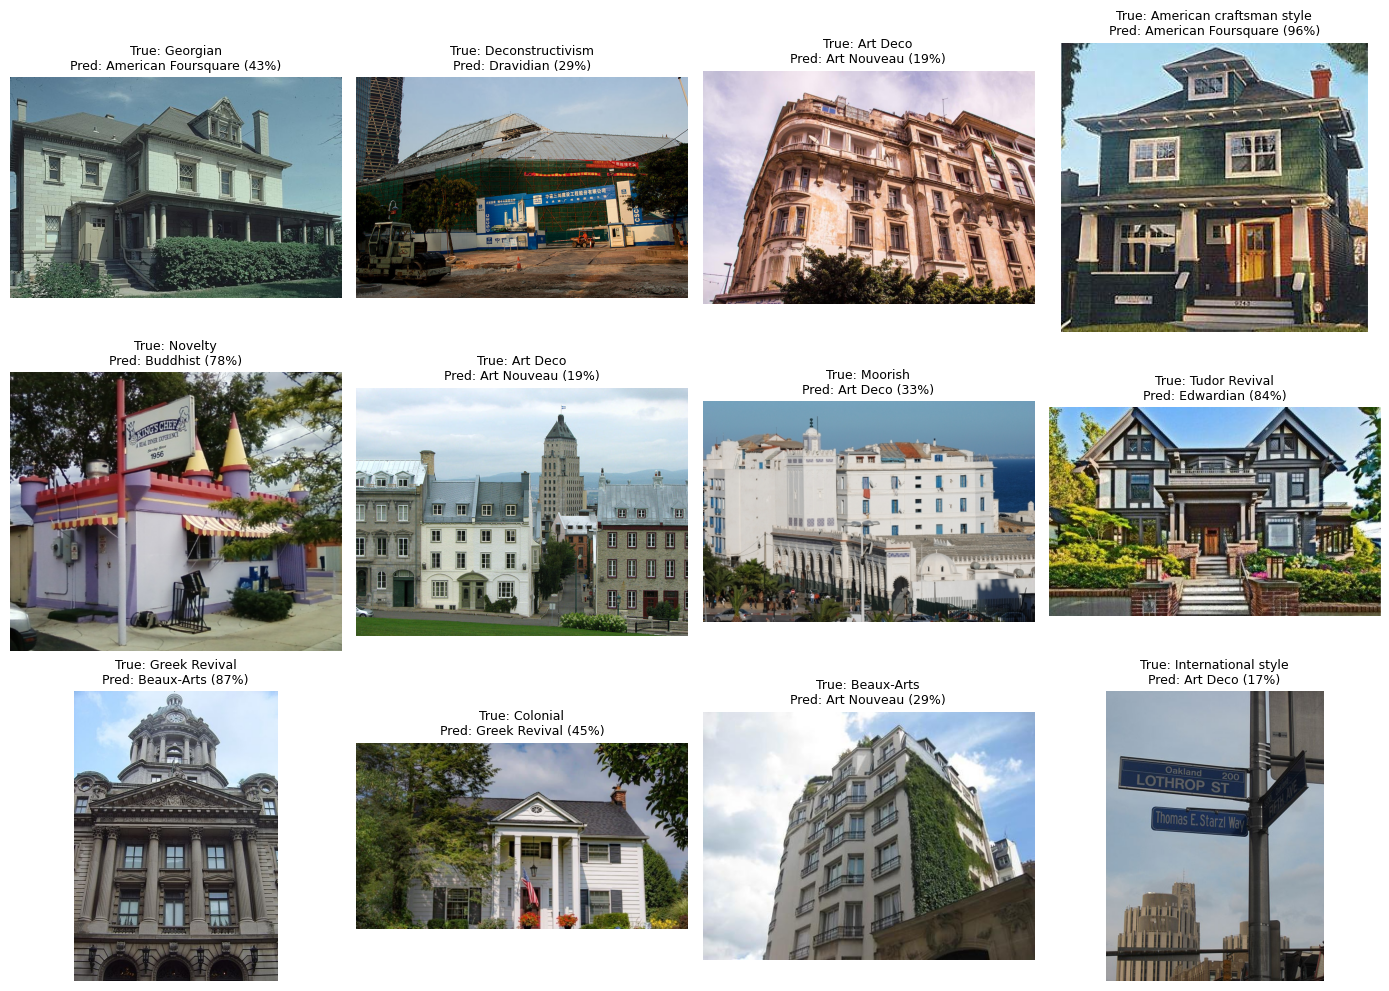

In [17]:
import os, json, numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

ROOT = '/content/data'
PROJECT = '/content/drive/MyDrive/heritage-lens'
dev = 'cuda'
assert os.path.exists(ROOT), 'Data missing: rerun the Kaggle download cell'
os.makedirs(f'{PROJECT}/outputs', exist_ok=True)

df = pd.read_csv(f'{PROJECT}/datasets/splits.csv')
classes = json.load(open(f'{PROJECT}/models/classes.json'))
c2i = {c: i for i, c in enumerate(classes)}
short = [c.replace(' architecture', '').replace('Architecture of the ', '').replace('Architecture of ', '') for c in classes]
test = df[df.split == 'test'].reset_index(drop=True)

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, d, tf):
        self.p, self.tf = d.path.tolist(), tf
        self.y = [c2i[l] for l in d.label]
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(f'{ROOT}/{self.p[i]}').convert('RGB')), self.y[i]

dl = DataLoader(DS(test, eval_tf), 64, shuffle=False, num_workers=2)

# load best model
model = models.resnet50()
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(classes)))
ck = torch.load(f'{PROJECT}/models/best.pt', map_location=dev, weights_only=False)
model.load_state_dict(ck['model']); model.to(dev).eval()

probs, labels = [], []
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    for x, y in dl:
        probs.append(torch.softmax(model(x.to(dev)).float(), 1).cpu()); labels += y.tolist()
probs = torch.cat(probs).numpy(); labels = np.array(labels); preds = probs.argmax(1)
top3 = np.argsort(-probs, 1)[:, :3]

# ---- headline numbers ----
p, r, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
print(f'Test images       : {len(labels)}')
print(f'Top-1 accuracy    : {accuracy_score(labels, preds):.3f}')
print(f'Top-3 accuracy    : {np.mean([l in t for l, t in zip(labels, top3)]):.3f}')
print(f'Macro precision   : {p:.3f}')
print(f'Macro recall      : {r:.3f}')
print(f'Macro F1          : {f1:.3f}')
print(f'Weighted F1       : {f1_score(labels, preds, average="weighted"):.3f}')

# ---- per-style report ----
rep = pd.DataFrame(classification_report(labels, preds, target_names=short,
                   output_dict=True, zero_division=0)).T.iloc[:len(classes)]
rep = rep.sort_values('f1-score')
rep.round(3).to_csv(f'{PROJECT}/outputs/per_style_report.csv')
print('\n--- 8 hardest styles (lowest F1) ---'); print(rep.head(8).round(3))
print('\n--- 8 easiest styles (highest F1) ---'); print(rep.tail(8).round(3))

# ---- most confused pairs ----
cm = confusion_matrix(labels, preds, labels=range(len(classes)))
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], short[i], short[j]) for i in range(len(classes)) for j in range(len(classes)) if off[i, j] > 0], reverse=True)[:10]
print('\n--- Most confused pairs (true -> predicted) ---')
for n, a, b in pairs: print(f'{n:3d}  {a}  ->  {b}')

# ---- confusion matrix (row-normalised) ----
cmn = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(16, 13))
sns.heatmap(cmn, cmap='Blues', xticklabels=short, yticklabels=short, vmin=0, vmax=1)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (share of each true style)')
plt.tight_layout(); plt.savefig(f'{PROJECT}/outputs/confusion_matrix.png', dpi=150); plt.show()

# ---- some mistakes ----
wrong = np.where(preds != labels)[0]
pick = np.random.default_rng(0).choice(wrong, 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, i in zip(axes.flat, pick):
    ax.imshow(Image.open(f'{ROOT}/{test.path[i]}').convert('RGB')); ax.axis('off')
    ax.set_title(f'True: {short[labels[i]]}\nPred: {short[preds[i]]} ({probs[i].max():.0%})', fontsize=9)
plt.tight_layout(); plt.savefig(f'{PROJECT}/outputs/mistakes.png', dpi=150); plt.show()

# save raw predictions
out = test[['path', 'label']].copy()
out['pred'] = [classes[i] for i in preds]
out.to_csv(f'{PROJECT}/outputs/test_predictions.csv', index=False)

7 images found


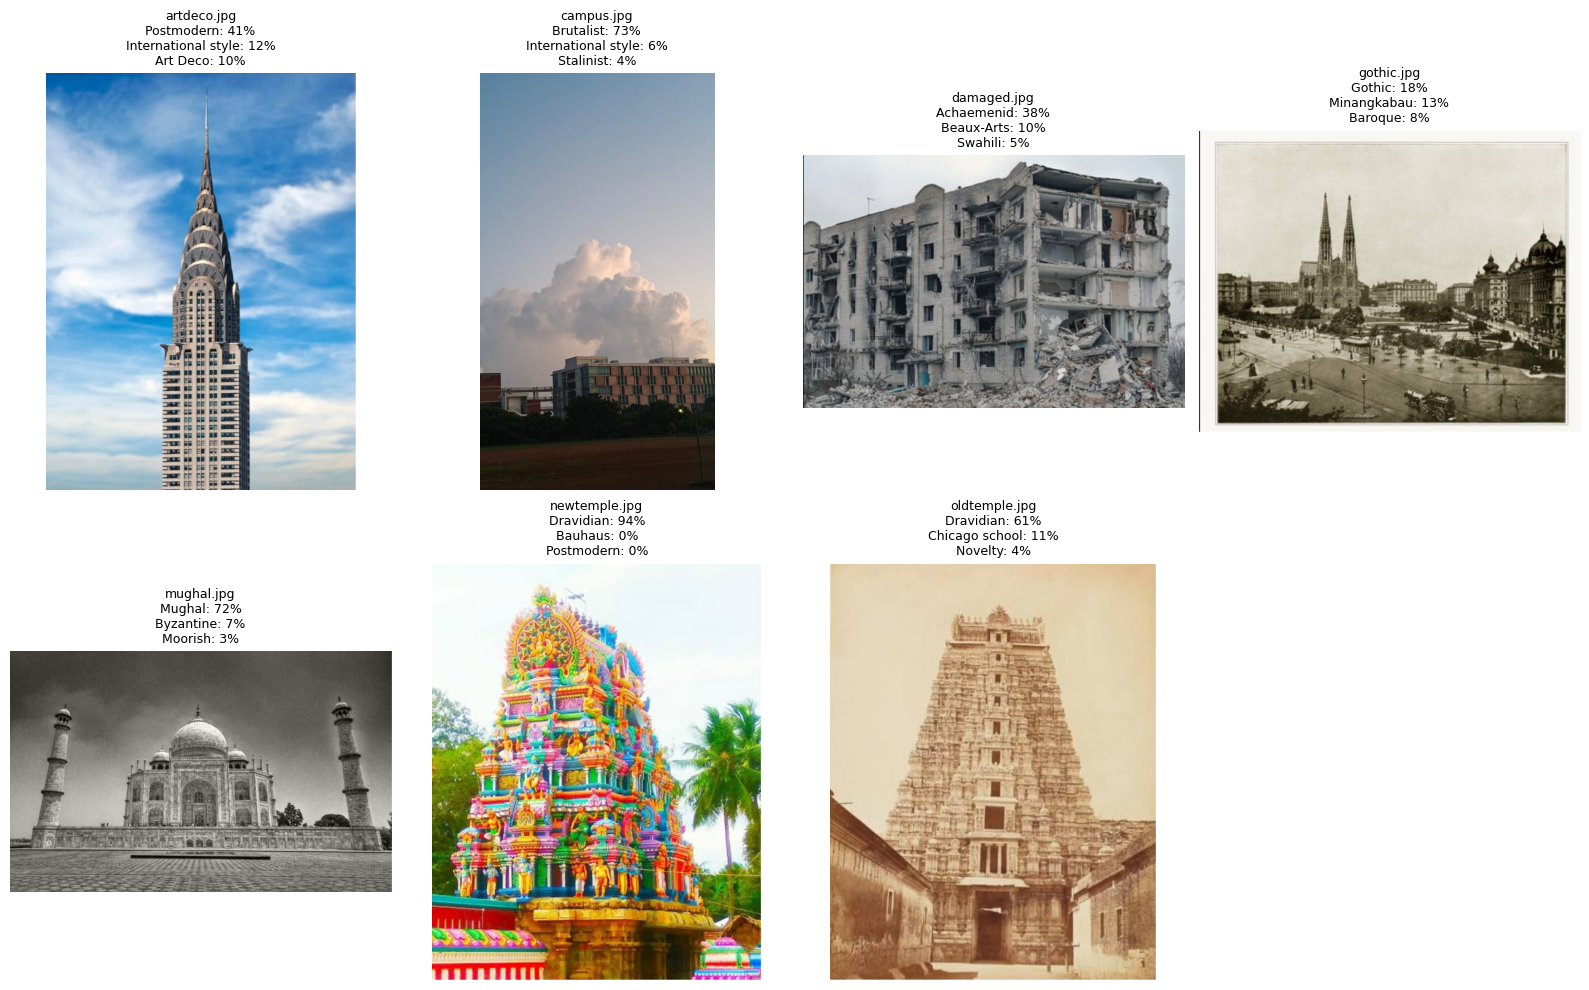

In [18]:
import os, json, glob, numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms

PROJECT = '/content/drive/MyDrive/heritage-lens'
dev = 'cuda'
classes = json.load(open(f'{PROJECT}/models/classes.json'))
short = [c.replace(' architecture', '').replace('Architecture of the ', '').replace('Architecture of ', '') for c in classes]

model = models.resnet50()
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(classes)))
model.load_state_dict(torch.load(f'{PROJECT}/models/best.pt', map_location=dev, weights_only=False)['model'])
model.to(dev).eval()

tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def predict_style(img, k=3):
    if isinstance(img, str): img = Image.open(img)
    img = img.convert('RGB')
    with torch.no_grad():
        p = torch.softmax(model(tf(img).unsqueeze(0).to(dev)), 1)[0].cpu()
    top = p.topk(k)
    return [(short[i], float(v)) for v, i in zip(top.values, top.indices)]

files = sorted(f for f in glob.glob(f'{PROJECT}/test_images/*.*')
               if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')))
print(len(files), 'images found')
cols = 4; rows = max(1, (len(files) + cols - 1) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
axes = np.atleast_1d(axes).flatten()
for ax in axes: ax.axis('off')
for ax, f in zip(axes, files):
    res = predict_style(f)
    ax.imshow(Image.open(f).convert('RGB'))
    ax.set_title(os.path.basename(f)[:30] + '\n' + '\n'.join(f'{n}: {p:.0%}' for n, p in res), fontsize=9)
plt.tight_layout()
plt.savefig(f'{PROJECT}/outputs/real_photo_results.png', dpi=150)
plt.show()

In [24]:
DESC = {
 'Achaemenid': 'Ancient Persian (c. 550-330 BC): monumental stone columns, grand staircases and relief carvings, as at Persepolis.',
 'Amazigh': 'Berber architecture of North Africa: fortified earthen villages, kasbahs and mud-brick towers.',
 'American Foursquare': 'Boxy American house (c. 1895-1930): hipped roof, wide front porch, central dormer.',
 'American craftsman style': 'Early 20th-century American homes: low gabled roofs, wide eaves, exposed rafters, tapered porch columns.',
 'Ancient Egyptian': 'Massive stone temples and pyramids with huge columns, pylon gateways and hieroglyph carvings.',
 'Edo Period': 'Japanese (1603-1868): wooden buildings, tiled roofs, castles and tea houses.',
 'Joseon Dynasty': 'Korean (1392-1897): curved tiled roofs, timber frames, palaces and hanok houses.',
 'Qing Dynasty': 'Chinese (1644-1912): imperial palaces with glazed-tile roofs, red walls and ornate wooden brackets.',
 'Art Deco': '1920s-30s: geometric, streamlined forms, stepped skyscraper tops and bold decoration.',
 'Art Nouveau': 'c. 1890-1910: flowing organic curves, floral ironwork and decorative glass.',
 'Balinese': 'Indonesian temples and compounds: carved stone gateways, tiered thatched shrines, open pavilions.',
 'Baroque': '17th-18th century European: dramatic curves, rich ornament, grand domes and facades.',
 'Bauhaus': 'German functional modernism (1919-33): plain cubic forms, flat roofs, white walls, large windows.',
 'Beaux-Arts': 'Late 19th century classical grandeur: symmetrical facades, columns, sculpture, mansard roofs.',
 'Brutalist': 'Mid-20th century: raw exposed concrete in massive, blocky forms.',
 'Buddhist': 'Temples, stupas, pagodas and monasteries with symmetrical layouts and Buddha imagery.',
 'Byzantine': 'Eastern Roman: large domes on round arches, rich mosaics, as in Hagia Sophia.',
 'Chicago school': 'Late 19th century early skyscrapers: steel frames, large windows, little ornament.',
 'Colonial': 'Settler-era style: symmetrical fronts, simple classical details, columned porches.',
 'Deconstructivism': 'Late 20th century: fragmented, angular, distorted shapes that break the regular box.',
 'Dravidian': 'South Indian temples: towering carved gopuram gateways, pillared halls and temple tanks.',
 'Edwardian': 'Early 1900s British: lighter than Victorian, red brick, big windows, restrained ornament.',
 'Georgian': 'British (1714-1830): symmetrical brick fronts, sash windows, classical proportions.',
 'Gothic': 'Medieval European: pointed arches, ribbed vaults, flying buttresses and tall spires.',
 'Greek Revival': 'Early-mid 19th century: temple-like fronts with columns and triangular pediments.',
 'Hausa': 'West African mud-brick buildings with decorative relief patterns.',
 'International style': 'Mid-20th century: glass-and-steel boxes, flat roofs, no ornament.',
 'Khmer': 'Cambodian (Angkor): sandstone temple mountains, towers, galleries and carved reliefs.',
 'Maya': 'Mesoamerican: stepped stone pyramids, temple platforms and corbelled vaults.',
 'Minangkabau': 'West Sumatra: rumah gadang houses with sweeping upturned horn-shaped roofs.',
 'Moorish': 'Islamic Iberia and North Africa: horseshoe arches, geometric tilework, courtyards.',
 'Mughal': 'Indo-Islamic (16th-18th century): onion domes, white marble, minarets, symmetrical layout, as in the Taj Mahal.',
 'Novelty': 'Buildings shaped like objects or with playful, eye-catching roadside designs.',
 'Ottoman': 'Large central domes with semi-domes and slender pencil-shaped minarets.',
 'Palladian': 'Inspired by Palladio: strict symmetry, temple-front porticos, classical villas.',
 'Postmodern': 'Late 20th century: playful mix of historical references, bold colours and ornament.',
 'Queen Anne': 'Late Victorian houses: asymmetry, turrets, wraparound porches, decorative shingles.',
 'Romanesque': '11th-12th century: thick walls, round arches, small windows, sturdy towers.',
 'Russian Revival': '19th century: onion domes, bright colours and ornamental patterns from medieval Russian churches.',
 'Safavid': 'Persian (1501-1736): tiled domes, iwans, blue and turquoise mosaics, as in Isfahan.',
 'Stalinist': 'Soviet mid-century: monumental symmetrical buildings and tiered "wedding cake" towers.',
 'Swahili': 'East African coast: coral-stone buildings, carved wooden doors, Islamic influence.',
 'Tudor Revival': 'Half-timbering, steep gables, tall chimneys and decorative brickwork.',
}
missing = [s for s in short if s not in DESC]
print('Styles without a description:', missing)   # should print []

import gradio as gr

def run(img):
    if img is None:
        return {}, 'Please upload a photo.', ''
    res = predict_style(img, k=3)
    name, p = res[0]
    if p >= 0.60:
        msg = f'Looks like {name} architecture ({p:.0%} confident).'
    elif p >= 0.35:
        msg = f'Probably {name}, but not certain ({p:.0%}). Check the other guesses.'
    else:
        msg = (f'Not sure. Best guess is {name} ({p:.0%}). The photo may be old or damaged, '
               f'or the style may not be one of the 43 the model knows.')
    return {n: pr for n, pr in res}, msg, DESC.get(name, '')

demo = gr.Interface(
    fn=run,
    inputs=gr.Image(type='pil', label='Upload a photo of a building'),
    outputs=[gr.Label(num_top_classes=3, label='Top 3 styles'),
             gr.Textbox(label='Result'),
             gr.Textbox(label='About the top guess')],
    title='Heritage Lens: Architectural Style Finder',
    description='Upload a photo (old or new) of a building and the model guesses its architectural style.',
)
demo.launch(share=True, debug=True)

Styles without a description: []
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f7850726512835f652.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://f7850726512835f652.gradio.live


In [6]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install gradio transformers

import os, json, glob, torch, torch.nn as nn
from PIL import Image
from torchvision import models, transforms
from transformers import CLIPModel, CLIPProcessor

PROJECT = '/content/drive/MyDrive/heritage-lens'
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', dev)

# --- style classifier ---
classes = json.load(open(f'{PROJECT}/models/classes.json'))
short = [c.replace(' architecture', '').replace('Architecture of the ', '').replace('Architecture of ', '') for c in classes]

model = models.resnet50()
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(classes)))
ck = torch.load(f'{PROJECT}/models/best.pt', map_location=dev, weights_only=False)
model.load_state_dict(ck['model']); model.to(dev).eval()

tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def predict_style(img, k=3):
    if isinstance(img, str): img = Image.open(img)
    img = img.convert('RGB')
    with torch.no_grad():
        p = torch.softmax(model(tf(img).unsqueeze(0).to(dev)), 1)[0].cpu()
    top = p.topk(k)
    return [(short[i], float(v)) for v, i in zip(top.values, top.indices)]

# --- "is this a building?" check (CLIP) ---
clip = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(dev).eval()
clip_proc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')

LABELS = [
    'a photo of a building',                   # first 3 count as "building"
    'a photo of a historic monument or temple',
    'a photo of a ruined or damaged building',
    'a photo of a person',
    'a selfie or portrait of a face',
    'a photo of an animal',
    'a photo of food',
    'a photo of a landscape or nature',
    'a photo of a vehicle',
    'a photo of an indoor room',
    'a screenshot or a document',
    'a photo of an everyday object',
]
N_BUILD = 3
BUILDING_MIN = 0.5

def building_score(img):
    inputs = clip_proc(text=LABELS, images=img.convert('RGB'), return_tensors='pt', padding=True).to(dev)
    with torch.no_grad():
        p = clip(**inputs).logits_per_image.softmax(1)[0].cpu()
    return float(p[:N_BUILD].sum()), LABELS[int(p.argmax())]

print('Ready')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Ready


In [7]:
for f in sorted(glob.glob(f'{PROJECT}/test_images/*.*')):
    s, c = building_score(Image.open(f))
    print(f'{os.path.basename(f):20s} building score {s:.2f}   closest: {c}')

artdeco.jpg          building score 0.99   closest: a photo of a building
campus.jpg           building score 0.39   closest: a photo of a building
damaged.jpg          building score 1.00   closest: a photo of a ruined or damaged building
gothic.jpg           building score 0.70   closest: a photo of a historic monument or temple
mughal.jpg           building score 0.99   closest: a photo of a historic monument or temple
newtemple.jpg        building score 1.00   closest: a photo of a historic monument or temple
oldtemple.jpg        building score 1.00   closest: a photo of a historic monument or temple


In [ ]:
import gradio as gr

DESC = {
 'Achaemenid': 'Ancient Persian (c. 550-330 BC): monumental stone columns, grand staircases and relief carvings, as at Persepolis.',
 'Amazigh': 'Berber architecture of North Africa: fortified earthen villages, kasbahs and mud-brick towers.',
 'American Foursquare': 'Boxy American house (c. 1895-1930): hipped roof, wide front porch, central dormer.',
 'American craftsman style': 'Early 20th-century American homes: low gabled roofs, wide eaves, exposed rafters, tapered porch columns.',
 'Ancient Egyptian': 'Massive stone temples and pyramids with huge columns, pylon gateways and hieroglyph carvings.',
 'Edo Period': 'Japanese (1603-1868): wooden buildings, tiled roofs, castles and tea houses.',
 'Joseon Dynasty': 'Korean (1392-1897): curved tiled roofs, timber frames, palaces and hanok houses.',
 'Qing Dynasty': 'Chinese (1644-1912): imperial palaces with glazed-tile roofs, red walls and ornate wooden brackets.',
 'Art Deco': '1920s-30s: geometric, streamlined forms, stepped skyscraper tops and bold decoration.',
 'Art Nouveau': 'c. 1890-1910: flowing organic curves, floral ironwork and decorative glass.',
 'Balinese': 'Indonesian temples and compounds: carved stone gateways, tiered thatched shrines, open pavilions.',
 'Baroque': '17th-18th century European: dramatic curves, rich ornament, grand domes and facades.',
 'Bauhaus': 'German functional modernism (1919-33): plain cubic forms, flat roofs, white walls, large windows.',
 'Beaux-Arts': 'Late 19th century classical grandeur: symmetrical facades, columns, sculpture, mansard roofs.',
 'Brutalist': 'Mid-20th century: raw exposed concrete in massive, blocky forms.',
 'Buddhist': 'Temples, stupas, pagodas and monasteries with symmetrical layouts and Buddha imagery.',
 'Byzantine': 'Eastern Roman: large domes on round arches, rich mosaics, as in Hagia Sophia.',
 'Chicago school': 'Late 19th century early skyscrapers: steel frames, large windows, little ornament.',
 'Colonial': 'Settler-era style: symmetrical fronts, simple classical details, columned porches.',
 'Deconstructivism': 'Late 20th century: fragmented, angular, distorted shapes that break the regular box.',
 'Dravidian': 'South Indian temples: towering carved gopuram gateways, pillared halls and temple tanks.',
 'Edwardian': 'Early 1900s British: lighter than Victorian, red brick, big windows, restrained ornament.',
 'Georgian': 'British (1714-1830): symmetrical brick fronts, sash windows, classical proportions.',
 'Gothic': 'Medieval European: pointed arches, ribbed vaults, flying buttresses and tall spires.',
 'Greek Revival': 'Early-mid 19th century: temple-like fronts with columns and triangular pediments.',
 'Hausa': 'West African mud-brick buildings with decorative relief patterns.',
 'International style': 'Mid-20th century: glass-and-steel boxes, flat roofs, no ornament.',
 'Khmer': 'Cambodian (Angkor): sandstone temple mountains, towers, galleries and carved reliefs.',
 'Maya': 'Mesoamerican: stepped stone pyramids, temple platforms and corbelled vaults.',
 'Minangkabau': 'West Sumatra: rumah gadang houses with sweeping upturned horn-shaped roofs.',
 'Moorish': 'Islamic Iberia and North Africa: horseshoe arches, geometric tilework, courtyards.',
 'Mughal': 'Indo-Islamic (16th-18th century): onion domes, white marble, minarets, symmetrical layout, as in the Taj Mahal.',
 'Novelty': 'Buildings shaped like objects or with playful, eye-catching roadside designs.',
 'Ottoman': 'Large central domes with semi-domes and slender pencil-shaped minarets.',
 'Palladian': 'Inspired by Palladio: strict symmetry, temple-front porticos, classical villas.',
 'Postmodern': 'Late 20th century: playful mix of historical references, bold colours and ornament.',
 'Queen Anne': 'Late Victorian houses: asymmetry, turrets, wraparound porches, decorative shingles.',
 'Romanesque': '11th-12th century: thick walls, round arches, small windows, sturdy towers.',
 'Russian Revival': '19th century: onion domes, bright colours and ornamental patterns from medieval Russian churches.',
 'Safavid': 'Persian (1501-1736): tiled domes, iwans, blue and turquoise mosaics, as in Isfahan.',
 'Stalinist': 'Soviet mid-century: monumental symmetrical buildings and tiered "wedding cake" towers.',
 'Swahili': 'East African coast: coral-stone buildings, carved wooden doors, Islamic influence.',
 'Tudor Revival': 'Half-timbering, steep gables, tall chimneys and decorative brickwork.',
}
print('Styles without a description:', [s for s in short if s not in DESC])   # should print []

def run(img):
    if img is None:
        return {}, 'Please upload a photo.', ''
    score, closest = building_score(img)
    if score < BUILDING_MIN:
        return {}, (f'This does not look like a building (closest match: "{closest}"). '
                    f'Please upload a photo of a building.'), ''
    res = predict_style(img, k=3)
    name, p = res[0]
    if p >= 0.60:
        msg = f'Looks like {name} architecture ({p:.0%} confident).'
    elif p >= 0.35:
        msg = f'Probably {name}, but not certain ({p:.0%}). Check the other guesses.'
    else:
        msg = (f'Not sure. Best guess is {name} ({p:.0%}). The photo may be old or damaged, '
               f'or the style may not be one of the 43 the model knows.')
    return {n: pr for n, pr in res}, msg, DESC.get(name, '')

demo = gr.Interface(
    fn=run,
    inputs=gr.Image(type='pil', label='Upload a photo of a building'),
    outputs=[gr.Label(num_top_classes=3, label='Top 3 styles'),
             gr.Textbox(label='Result'),
             gr.Textbox(label='About the top guess')],
    title='Heritage Lens: Architectural Style Finder',
    description='Upload a photo (old or new) of a building and the model guesses its architectural style.',
)
demo.launch(share=True, debug=True)

Styles without a description: []
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://57ff3ec5780e3b9966.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [9]:
import glob, os
from PIL import Image

print('--- NON-buildings (want LOW scores) ---')
for f in sorted(glob.glob(f'{PROJECT}/negative_tests/*.*')):
    s, c = building_score(Image.open(f))
    print(f'{os.path.basename(f):25s} building score {s:.2f}   closest: {c}')

print('\n--- Buildings (want HIGH scores) ---')
for f in sorted(glob.glob(f'{PROJECT}/test_images/*.*')):
    s, c = building_score(Image.open(f))
    print(f'{os.path.basename(f):25s} building score {s:.2f}')

--- NON-buildings (want LOW scores) ---
campus.jpg                building score 0.39   closest: a photo of a building
ivan-zhuldybin-5sH2_iWpYI0-unsplash.jpg building score 0.01   closest: a photo of a vehicle
jilbert-ebrahimi-kj4fRRj5Tqc-unsplash.jpg building score 0.00   closest: a photo of an indoor room
monaz-hastam-qk6EjQHVLkY-unsplash.jpg building score 0.00   closest: a photo of food
walid-elmarkou-u46jOP_8LTA-unsplash.jpg building score 0.00   closest: a photo of an animal

--- Buildings (want HIGH scores) ---
artdeco.jpg               building score 0.99
campus.jpg                building score 0.39
damaged.jpg               building score 1.00
gothic.jpg                building score 0.70
mughal.jpg                building score 0.99
newtemple.jpg             building score 1.00
oldtemple.jpg             building score 1.00


In [10]:
BUILDING_MIN = 0.2
print('Cut-off set to', BUILDING_MIN)

Cut-off set to 0.2
